In [1]:
import pandas as pd  
  
# Load the dataset  
df = pd.read_csv('./data/resale_transactions.csv')

df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,resale_price,town_id,flatm_id,town_name,flatm_name
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,07 TO 09,123.0,1989,70 years 03 months,488000.0,17,5,PASIR RIS,Improved
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,01 TO 03,100.0,1999,81,345000.0,21,8,SENGKANG,Model A
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,19 TO 21,110.0,2002,82 years 06 months,370000.0,9,5,CHOA CHU KANG,Improved
3,4,2015-12,4 ROOM,130,LOR AH SOO,13 TO 15,103.0,1984,67,432000.0,12,8,HOUGANG,Model A
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,07 TO 09,122.0,1992,74 years 02 months,500000.0,22,5,SERANGOON,Improved


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 88688 entries, 0 to 88687
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   88688 non-null  int64  
 1   month                88688 non-null  str    
 2   flat_type            88688 non-null  str    
 3   block                88688 non-null  str    
 4   street_name          88688 non-null  str    
 5   storey_range         88688 non-null  str    
 6   floor_area_sqm       88688 non-null  float64
 7   lease_commence_date  88688 non-null  int64  
 8   remaining_lease      88688 non-null  str    
 9   resale_price         88688 non-null  float64
 10  town_id              88688 non-null  int64  
 11  flatm_id             88688 non-null  int64  
 12  town_name            87905 non-null  str    
 13  flatm_name           88174 non-null  str    
dtypes: float64(2), int64(4), str(8)
memory usage: 9.5 MB


In [3]:
# Detecting Missing Values 
df.isnull().sum()

id                       0
month                    0
flat_type                0
block                    0
street_name              0
storey_range             0
floor_area_sqm           0
lease_commence_date      0
remaining_lease          0
resale_price             0
town_id                  0
flatm_id                 0
town_name              783
flatm_name             514
dtype: int64

In [4]:
# Descriptive Statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,88688.0,42233.303739,24376.312037,1.0,21136.75,42228.5,63339.25,84465.0
floor_area_sqm,88688.0,97.520444,24.197379,31.0,76.00,96.0,112.00,280.0
lease_commence_date,88688.0,1570.225352,1226.315949,-2016.0,1980.00,1988.0,2000.00,2016.0
resale_price,88688.0,438679.303299,146670.254508,160000.0,335000.00,408000.0,505000.00,1200000.0
town_id,88688.0,14.631337,8.032285,1.0,8.00,15.0,22.00,26.0
flatm_id,88688.0,8.889185,3.906898,1.0,5.00,8.0,12.00,21.0


In [5]:
# Checking for Duplicates
df.duplicated().sum()

np.int64(4223)

In [6]:
# Identifying and Sorting Duplicates
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,resale_price,town_id,flatm_id,town_name,flatm_name
103,104,2016-09,3 ROOM,201E,TAMPINES ST 23,04 TO 06,68.0,-1987,70,305000.0,23,12,TAMPINES,New Generation
88570,104,2016-09,3 ROOM,201E,TAMPINES ST 23,04 TO 06,68.0,-1987,70,305000.0,23,12,TAMPINES,New Generation
106,107,2015-08,4 ROOM,146,SERANGOON NTH AVE 1,13 TO 15,83.0,-1987,70,355000.0,22,17,SERANGOON,Simplified
88156,107,2015-08,4 ROOM,146,SERANGOON NTH AVE 1,13 TO 15,83.0,-1987,70,355000.0,22,17,SERANGOON,Simplified
114,115,2017-03,4 ROOM,274D,PUNGGOL PL,16 TO 18,93.0,2013,95 years 04 months,560000.0,18,13,PUNGGOL,Premium Apartment
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87372,84427,2019-01,5 ROOM,348D,YISHUN AVE 11,13 TO 15,112.0,2013,93 years 09 months,758000.0,26,4,YISHUN,DBSS
84428,84429,2018-10,4 ROOM,838,HOUGANG CTRL,04 TO 06,100.0,-1997,77 years 05 months,530000.0,12,8,HOUGANG,Model A
85835,84429,2018-10,4 ROOM,838,HOUGANG CTRL,04 TO 06,100.0,-1997,77 years 05 months,530000.0,12,8,HOUGANG,Model A
84461,84462,2015-06,5 ROOM,596A,ANG MO KIO ST 52,07 TO 09,110.0,2002,86,760000.0,1,5,ANG MO KIO,Improved


In [7]:
# Reomoving Duplicates
df.drop_duplicates(inplace=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 84465 entries, 0 to 84464
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   84465 non-null  int64  
 1   month                84465 non-null  str    
 2   flat_type            84465 non-null  str    
 3   block                84465 non-null  str    
 4   street_name          84465 non-null  str    
 5   storey_range         84465 non-null  str    
 6   floor_area_sqm       84465 non-null  float64
 7   lease_commence_date  84465 non-null  int64  
 8   remaining_lease      84465 non-null  str    
 9   resale_price         84465 non-null  float64
 10  town_id              84465 non-null  int64  
 11  flatm_id             84465 non-null  int64  
 12  town_name            83724 non-null  str    
 13  flatm_name           83977 non-null  str    
dtypes: float64(2), int64(4), str(8)
memory usage: 9.0 MB


In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

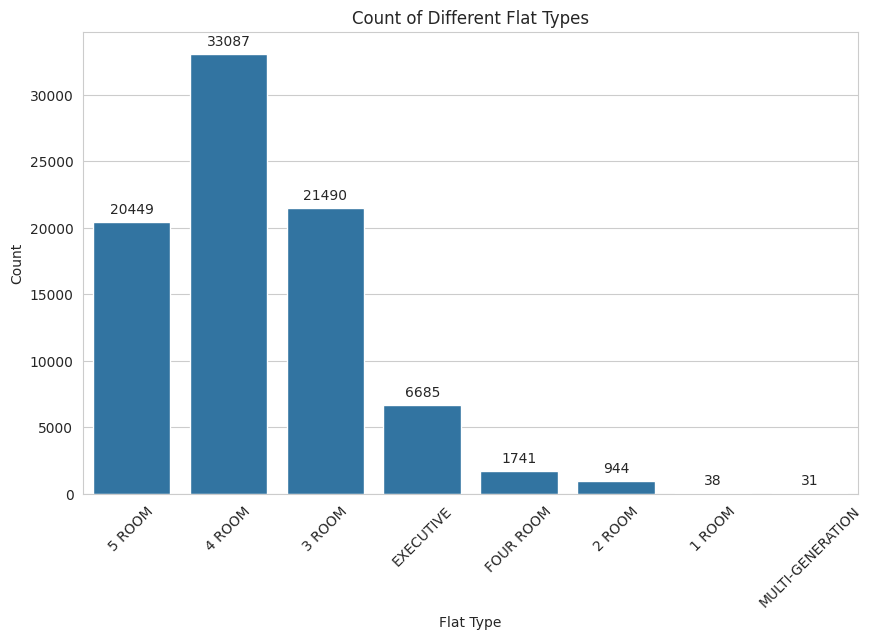

In [9]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for flat type with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='flat_type', data=df)
plt.title('Count of Different Flat Types')
plt.xlabel('Flat Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

In [10]:
# Replace 'FOUR ROOM' with '4 ROOM' in the 'flat_type' column
df['flat_type'] = df['flat_type'].replace('FOUR ROOM', '4 ROOM')
  
# Verify the changes
print(df['flat_type'].value_counts())

flat_type
4 ROOM              34828
3 ROOM              21490
5 ROOM              20449
EXECUTIVE            6685
2 ROOM                944
1 ROOM                 38
MULTI-GENERATION       31
Name: count, dtype: int64


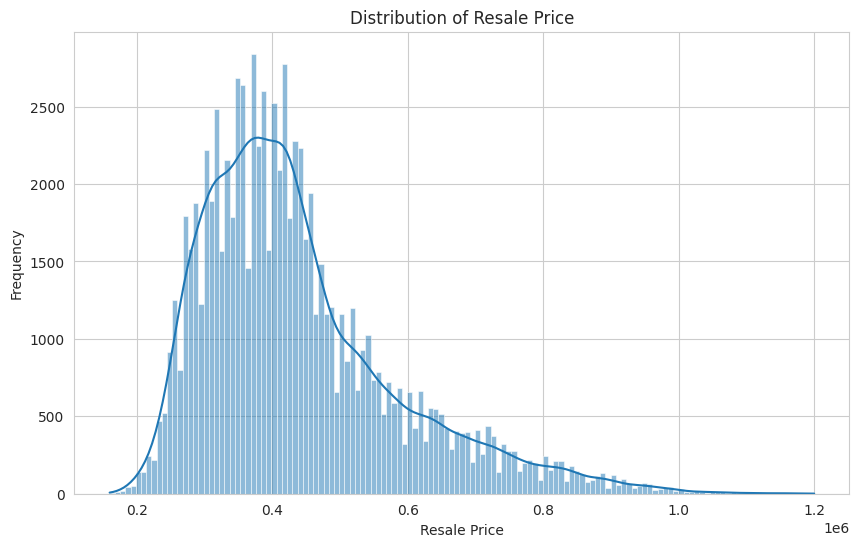

In [11]:
# Set the aesthetic style of the plots  
sns.set_style("whitegrid")  
  
# Histogram for resale price  
plt.figure(figsize=(10, 6))  
sns.histplot(df['resale_price'], kde=True)  
plt.title('Distribution of Resale Price')  
plt.xlabel('Resale Price')  
plt.ylabel('Frequency')  
plt.show()


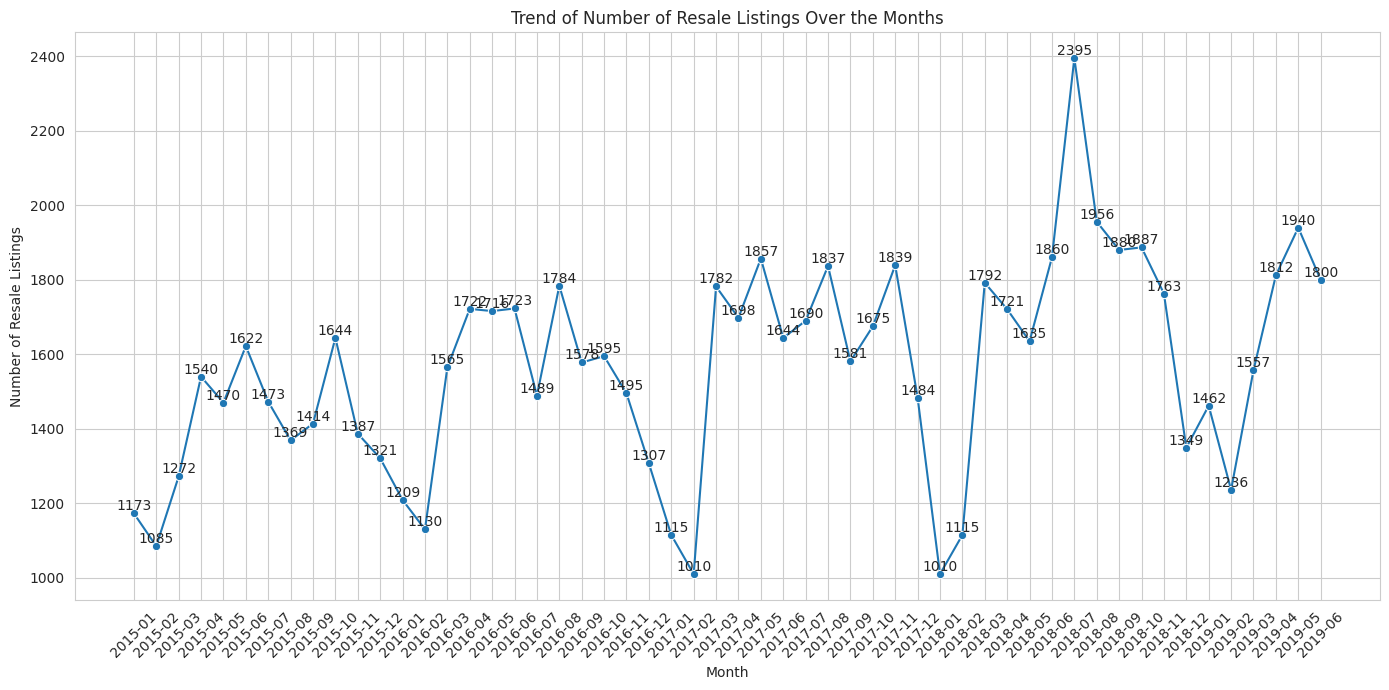

In [12]:
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Listings by Month
month_counts = df['month'].value_counts().sort_index()

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=month_counts.index, y=month_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(month_counts.index, month_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Resale Listings Over the Months')
plt.xlabel('Month')
plt.ylabel('Number of Resale Listings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

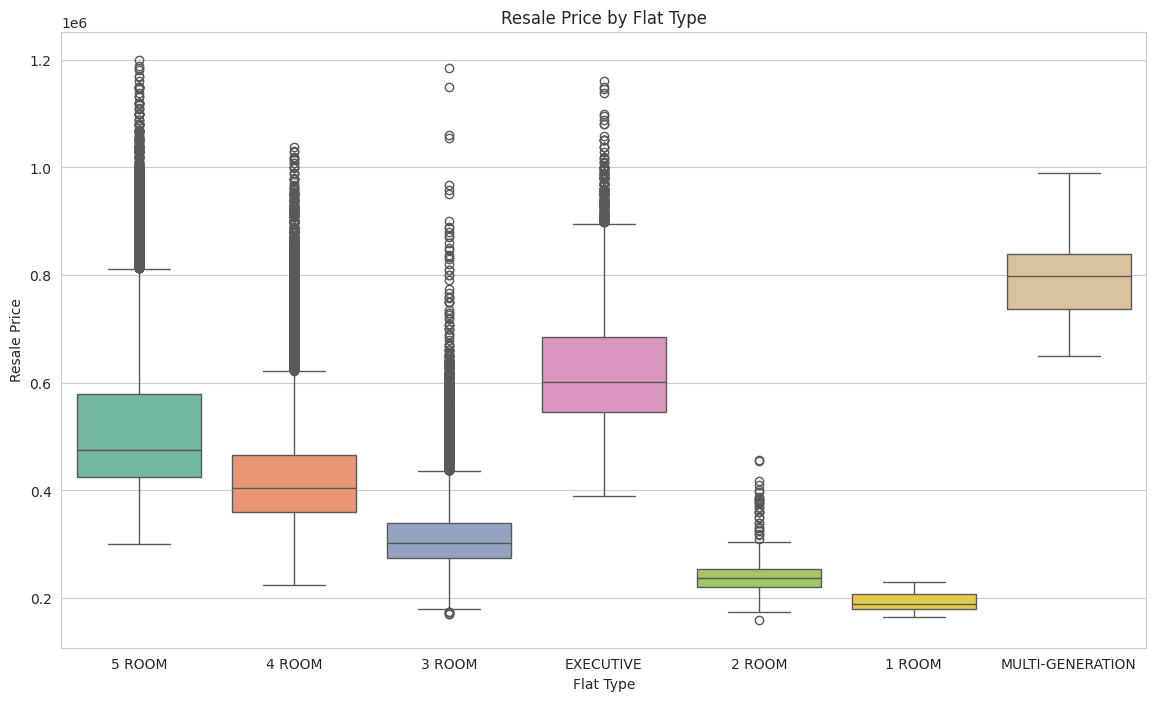

In [13]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Box plot for flat_type vs resale_price  
plt.figure(figsize=(14, 8))  
sns.boxplot(x='flat_type', y='resale_price', data=df, hue='flat_type', palette='Set2')  
plt.title('Resale Price by Flat Type')
plt.xlabel('Flat Type')
plt.ylabel('Resale Price')
plt.xticks(rotation=0)
plt.show()

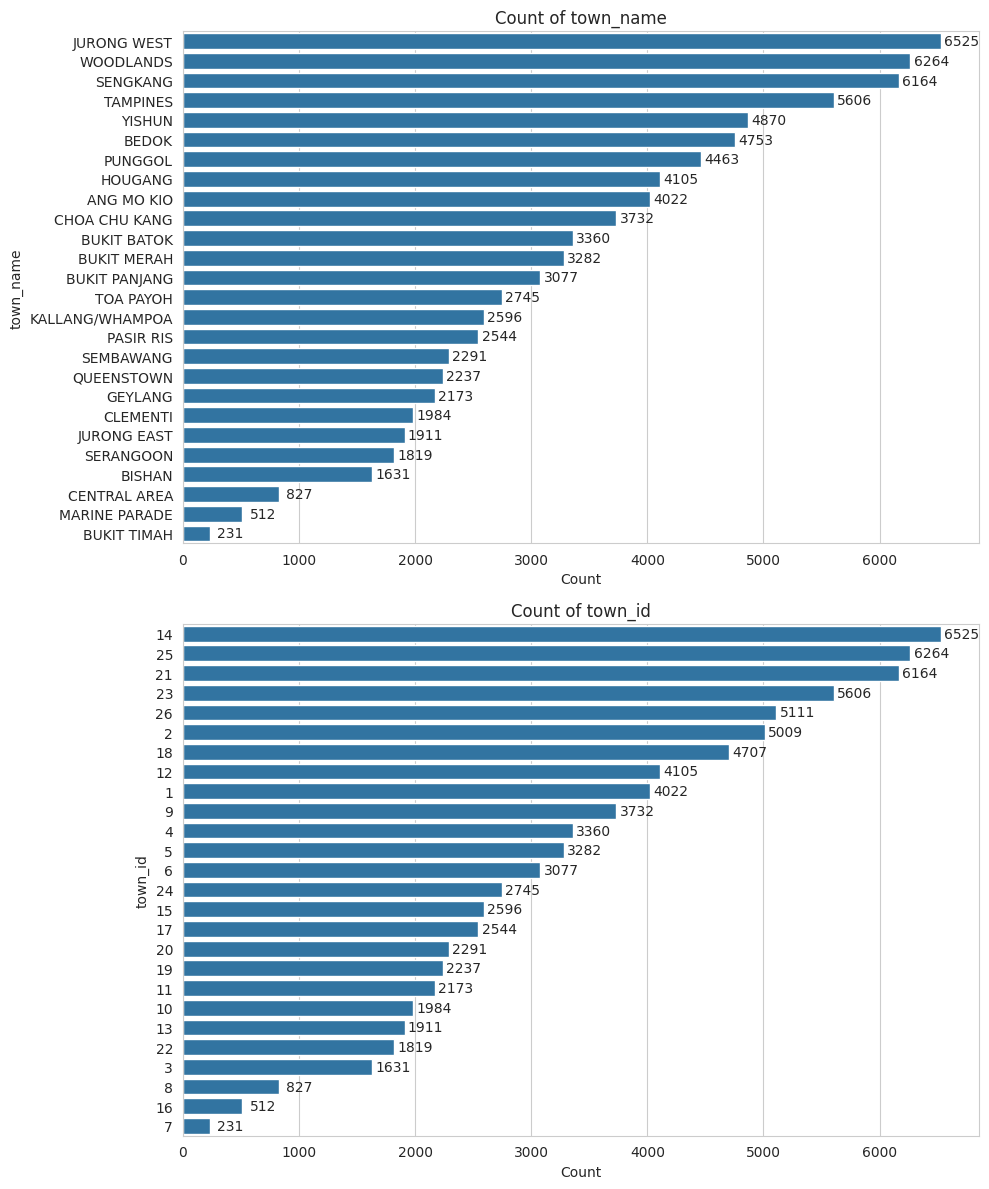

In [14]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Create a figure with 2 subplots (one above the other)
fig, axes = plt.subplots(2, 1, figsize=(10, 12))

# Sort the town_name by count
sorted_town_name = df['town_name'].value_counts().index

# Count plot for town_name with annotations
count_plot_1 = sns.countplot(y='town_name', data=df, order=sorted_town_name, ax=axes[0])
axes[0].set_title('Count of town_name')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('town_name')

# Annotate the bars with the frequency count
for p in count_plot_1.patches:
    count_plot_1.annotate(format(p.get_width(), '.0f'),
                          (p.get_width(), p.get_y() + p.get_height() / 2),
                          ha='center', va='center',
                          xytext=(15, 0),
                          textcoords='offset points')

# Sort the town_id by count
sorted_town_id = df['town_id'].value_counts().index

# Count plot for town_id with annotations
count_plot_2 = sns.countplot(y='town_id', data=df, order=sorted_town_id, ax=axes[1])
axes[1].set_title('Count of town_id')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('town_id')

# Annotate the bars with the frequency count
for p in count_plot_2.patches:
    count_plot_2.annotate(format(p.get_width(), '.0f'),
                          (p.get_width(), p.get_y() + p.get_height() / 2),
                          ha='center', va='center',
                          xytext=(15, 0),
                          textcoords='offset points')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the combined plot
plt.show()

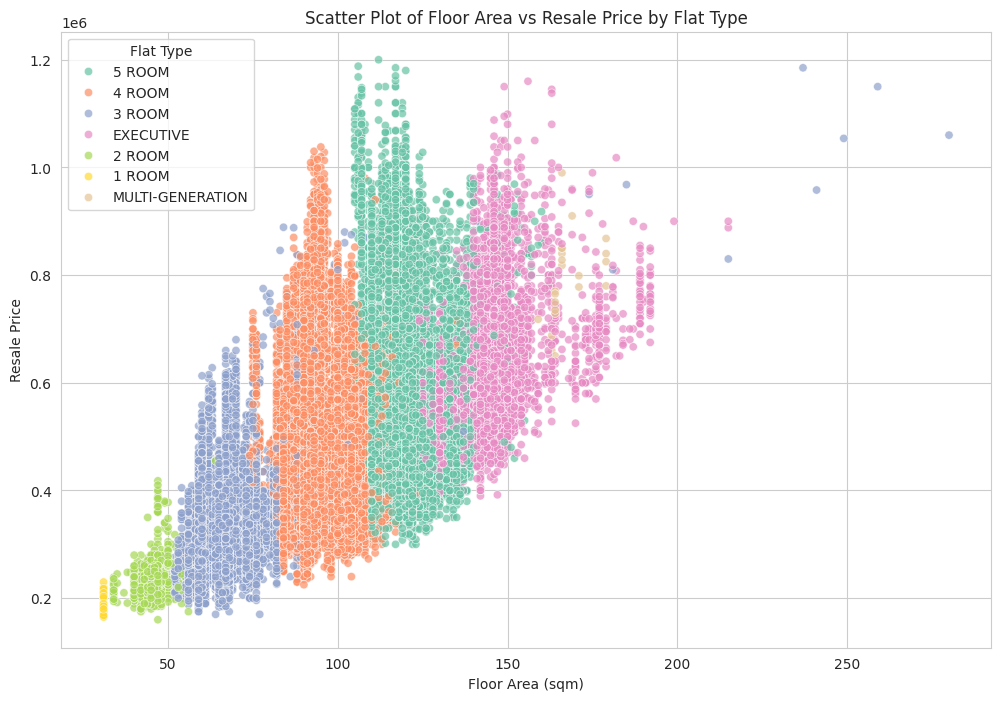

In [15]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Scatter plot for floor area vs resale price with color encoding for flat type
plt.figure(figsize=(12, 8))
sns.scatterplot(x='floor_area_sqm', y='resale_price', hue='flat_type', data=df, palette='Set2', alpha=0.7)
plt.title('Scatter Plot of Floor Area vs Resale Price by Flat Type')
plt.xlabel('Floor Area (sqm)')
plt.ylabel('Resale Price')
plt.legend(title='Flat Type')
plt.show()

In [16]:
# Filter the data for outliers
outliers = df[(df['flat_type'] == '3 ROOM') & 
                        (df['floor_area_sqm'] > 150) & 
                        (df['resale_price'] > 800000)]

# Display the outliers
outliers

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,resale_price,town_id,flatm_id,town_name,flatm_name
856,857,2018-09,3 ROOM,41,JLN BAHAGIA,01 TO 03,237.0,1972,52 years 10 months,1185000.0,15,19,KALLANG/WHAMPOA,Terrace
7472,7473,2018-06,3 ROOM,58,JLN MA'MOR,01 TO 03,174.0,1972,53 years 02 months,950000.0,15,19,KALLANG/WHAMPOA,Terrace
31858,31859,2015-03,3 ROOM,53,JLN MA'MOR,01 TO 03,280.0,1972,56,1060000.0,15,19,KALLANG/WHAMPOA,Terrace
47739,47740,2017-12,3 ROOM,65,JLN MA'MOR,01 TO 03,249.0,1972,53 years 07 months,1053888.0,15,19,KALLANG/WHAMPOA,Terrace
51992,51993,2018-05,3 ROOM,44,JLN BAHAGIA,01 TO 03,185.0,1972,53 years 02 months,968000.0,15,19,KALLANG/WHAMPOA,Terrace
54578,54579,2016-12,3 ROOM,57,JLN MA'MOR,01 TO 03,259.0,1972,54,1150000.0,15,19,KALLANG/WHAMPOA,Terrace
61997,61998,2017-05,3 ROOM,59,JLN MA'MOR,01 TO 03,181.0,1972,54 years 02 months,810000.0,15,19,KALLANG/WHAMPOA,Terrace
66428,66429,2017-06,3 ROOM,38,JLN BAHAGIA,01 TO 03,215.0,1972,54 years 01 month,830000.0,15,19,KALLANG/WHAMPOA,Terrace
78787,78788,2015-06,3 ROOM,60,JLN BAHAGIA,01 TO 03,241.0,1972,56,958000.0,15,19,KALLANG/WHAMPOA,Terrace


In [17]:
# Further filter the data for 3-room terrace flats
terrace_outliers = df[(df['flat_type'] == '3 ROOM') & 
                        (df['flatm_name'] == "Terrace")]

# Display the outliers
terrace_outliers.describe().T

,count,mean,std,min,25%,50%,75%,max
id,48.0,48168.062500,22777.117131,857.0,31793.75,51140.5,65752.50,83890.0
floor_area_sqm,48.0,117.708333,55.604974,78.0,83.00,93.0,113.25,280.0
lease_commence_date,48.0,1889.166667,569.171078,-1972.0,1972.00,1972.0,1972.00,1972.0
resale_price,48.0,813840.685000,122974.848464,635000.0,730000.00,795000.0,871250.00,1185000.0
town_id,48.0,15.666667,1.506487,15.0,15.00,15.0,15.00,19.0
flatm_id,48.0,19.000000,0.000000,19.0,19.00,19.0,19.00,19.0


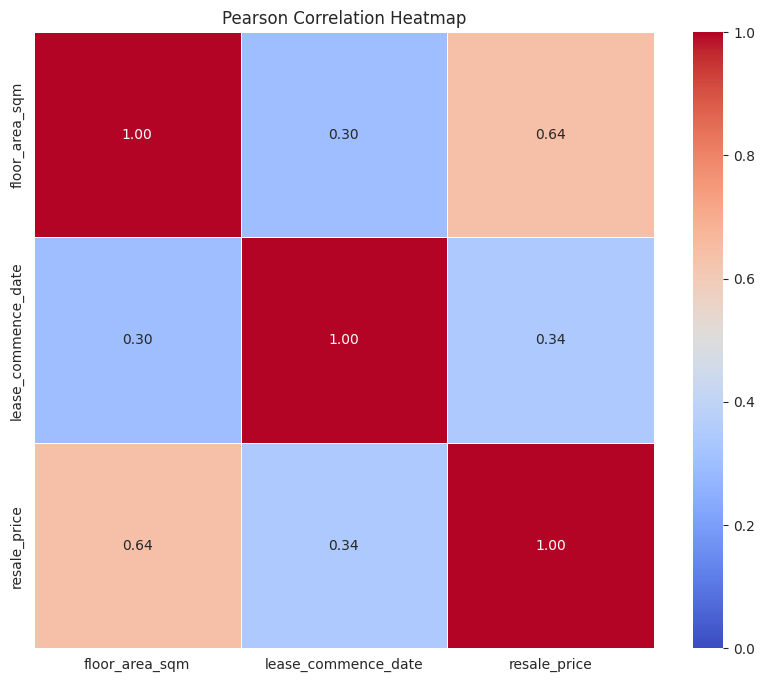

In [18]:
# Absolute negative years values
df['lease_commence_date'] = df['lease_commence_date'].abs()  
  
# Select continuous variables  
continuous_vars_all = df[['floor_area_sqm', 'lease_commence_date', 'resale_price']]

# Calculate the Pearson correlation matrix for the entire dataset
corr_matrix_pear = continuous_vars_all.corr(method='pearson')

# Plot the heatmap of the correlation matrix for the entire dataset
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix_pear, annot=True, cmap='coolwarm', vmin=0, center=0.5, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Pearson Correlation Heatmap')
plt.show()

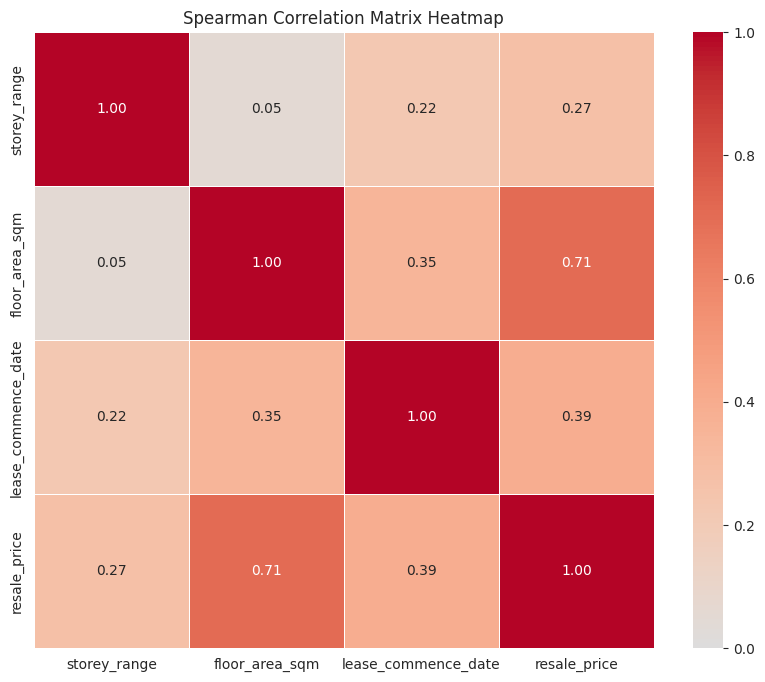

In [19]:
# Function to convert storey_range to ordinal scale by taking the average of the range
def convert_storey_range(storey_range: str) -> float:
    """
    Converts a storey range string into its average numerical value.
    
    The function takes a storey range in the format 'XX TO YY', splits it into two parts,
    converts these parts to integers, and returns the average of these integers.
    
    Args:
        storey_range (str): A string representing a range of storeys, in the format 'XX TO YY'.
        
    Returns:
        float: The average value of the two storeys in the range.
        
    Example:
        convert_storey_range('07 TO 09') -> 8.0
    """
    range_values = storey_range.split(' TO ')
    return (int(range_values[0]) + int(range_values[1])) / 2

# Use the .apply() method to convert the 'storey_range' column with the function
df['storey_range'] = df['storey_range'].apply(convert_storey_range)

# Select relevant columns for correlation analysis
spearman_vars = df[['storey_range', 'floor_area_sqm', 'lease_commence_date', 'resale_price']]

# Compute the Spearman correlation matrix
spearman_corr = spearman_vars.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

In [20]:
def fill_missing_names(df: pd.DataFrame, id_column: str, name_column: str) -> pd.DataFrame:
    """
    Fills missing values in the 'name_column' using the 'id_column'.

    Args (Arguments):
        df (pd.DataFrame): The DataFrame containing the columns to be filled.
        id_column (str): The name of the column containing the IDs.
        name_column (str): The name of the column containing the names to be filled.

    Returns:
        pd.DataFrame: The DataFrame with missing values in 'name_column' filled.
    """
    # Identify missing values in the 'name_column'
    missing_names = df[name_column].isna()

    # Create a dictionary mapping 'id_column' to 'name_column'
    name_mapping = df[[id_column, name_column]].dropna().drop_duplicates().set_index(id_column)[name_column].to_dict()

    # Fill missing 'name_column' using the mapping
    df.loc[missing_names, name_column] = df.loc[missing_names, id_column].map(name_mapping)

    return df

In [21]:
# Fill missing values in 'town_name' column
df = fill_missing_names(df=df, id_column='town_id', name_column='town_name')

# Fill missing values in 'flatm_name' column
df = fill_missing_names(df=df, id_column='flatm_id', name_column='flatm_name')

In [22]:
df.drop_duplicates(inplace=True)

In [23]:
# Convert 'month' column to datetime
df['year_month'] = pd.to_datetime(df['month'], format='%Y-%m')

# Extract year and month from the datetime object
df['year'] = df['year_month'].dt.year
df['month'] = df['year_month'].dt.month

df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,resale_price,town_id,flatm_id,town_name,flatm_name,year_month,year
0,1,5,5 ROOM,118,PASIR RIS ST 11,8.0,123.0,1989,70 years 03 months,488000.0,17,5,PASIR RIS,Improved,2018-05-01,2018
1,2,10,4 ROOM,101,RIVERVALE WALK,2.0,100.0,1999,81,345000.0,21,8,SENGKANG,Model A,2016-10-01,2016
2,3,10,5 ROOM,688A,CHOA CHU KANG DR,20.0,110.0,2002,82 years 06 months,370000.0,9,5,CHOA CHU KANG,Improved,2018-10-01,2018
3,4,12,4 ROOM,130,LOR AH SOO,14.0,103.0,1984,67,432000.0,12,8,HOUGANG,Model A,2015-12-01,2015
4,5,9,5 ROOM,533,SERANGOON NTH AVE 4,8.0,122.0,1992,74 years 02 months,500000.0,22,5,SERANGOON,Improved,2017-09-01,2017


In [24]:
# drop year_month
df = df.drop(columns=['year_month'])

In [25]:
import re

def extract_lease_info(lease_str: str) -> int:
    """
    Convert lease information from a string format to total months.

    This function takes a string representing the remaining lease period, which
    may include years and months in various formats (e.g., "70 years 3 months",
    "85 years", "67"), and converts it to the total number of months.

    Args:
        lease_str (str): The remaining lease period as a string.

    Returns:
        int: The total number of months, or None if the input is NaN.
    """

    if pd.isna(lease_str):
        return None
    
    # Regular expression to extract years and months
    years_match = re.search(r'(\d+)\s*years?', lease_str)
    months_match = re.search(r'(\d+)\s*months?', lease_str)
    number_match = re.match(r'^\d+$', lease_str.strip())
    
    if years_match:
        years = int(years_match.group(1))
    elif number_match:  # If only a number is present, assume it's in years
        years = int(number_match.group(0))
    else:
        years = 0
        
    months = int(months_match.group(1)) if months_match else 0
    
    # Convert the total lease period to months
    total_months = years * 12 + months
    return total_months

In [26]:
# Extract lease information  
df['remaining_lease_months'] = df['remaining_lease'].apply(extract_lease_info) 
# Display a random sample of the data to check the transformation
df[['remaining_lease', 'remaining_lease_months']].sample(5)

,remaining_lease,remaining_lease_months
48766,66 years 10 months,802
80760,51 years,612
66487,62,744
51297,67 years 09 months,813
51533,55 years 11 months,671


In [27]:
# Drop the 'remaining_lease' column
df = df.drop(columns=['remaining_lease'])

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 84465 entries, 0 to 84464
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      84465 non-null  int64  
 1   month                   84465 non-null  int32  
 2   flat_type               84465 non-null  str    
 3   block                   84465 non-null  str    
 4   street_name             84465 non-null  str    
 5   storey_range            84465 non-null  float64
 6   floor_area_sqm          84465 non-null  float64
 7   lease_commence_date     84465 non-null  int64  
 8   resale_price            84465 non-null  float64
 9   town_id                 84465 non-null  int64  
 10  flatm_id                84465 non-null  int64  
 11  town_name               84465 non-null  str    
 12  flatm_name              84465 non-null  str    
 13  year                    84465 non-null  int32  
 14  remaining_lease_months  84465 non-null  int64  
d

In [29]:
# Separate the data into features and target
X = df.drop(columns='resale_price')
y = df['resale_price']

In [30]:
# Show X - Note the uppercase
X

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,town_id,flatm_id,town_name,flatm_name,year,remaining_lease_months
0,1,5,5 ROOM,118,PASIR RIS ST 11,8.0,123.0,1989,17,5,PASIR RIS,Improved,2018,843
1,2,10,4 ROOM,101,RIVERVALE WALK,2.0,100.0,1999,21,8,SENGKANG,Model A,2016,972
2,3,10,5 ROOM,688A,CHOA CHU KANG DR,20.0,110.0,2002,9,5,CHOA CHU KANG,Improved,2018,990
3,4,12,4 ROOM,130,LOR AH SOO,14.0,103.0,1984,12,8,HOUGANG,Model A,2015,804
4,5,9,5 ROOM,533,SERANGOON NTH AVE 4,8.0,122.0,1992,22,5,SERANGOON,Improved,2017,890
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84460,84461,9,5 ROOM,352C,CANBERRA RD,11.0,111.0,2001,20,5,SEMBAWANG,Improved,2015,1020
84461,84462,6,5 ROOM,596A,ANG MO KIO ST 52,8.0,110.0,2002,1,5,ANG MO KIO,Improved,2015,1032
84462,84463,9,5 ROOM,979A,BUANGKOK CRES,2.0,110.0,2003,12,5,HOUGANG,Improved,2017,1018
84463,84464,4,4 ROOM,474,ANG MO KIO AVE 10,2.0,91.0,1984,1,12,ANG MO KIO,New Generation,2016,792


In [31]:
y

0        488000.0
1        345000.0
2        370000.0
3        432000.0
4        500000.0
           ...   
84460    468000.0
84461    760000.0
84462    380000.0
84463    406000.0
84464    425000.0
Name: resale_price, Length: 84465, dtype: float64

In [32]:
from sklearn.model_selection import train_test_split

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [33]:
# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (67572, 14) (67572,)
Validation set shape: (8446, 14) (8446,)
Test set shape: (8447, 14) (8447,)


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define numerical features to be standardized
numerical_features = ['floor_area_sqm', 'remaining_lease_months', 'lease_commence_date', 'year']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

In [43]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nomial features to be one-hot encoded
nominal_features = ['month', 'town_name', 'flatm_name']

# Define ordinal features to be ordinally encoded
ordinal_features = ['flat_type']

# Define the ordinal categories for flat_type
flat_type_categories = ['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'MULTI-GENERATION', 'EXECUTIVE']

# Define passthrough features that will not be transformed
passthrough_features = ['storey_range']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create an ordinal transformer pipeline
ordinal_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(categories=[flat_type_categories], handle_unknown='use_encoded_value', unknown_value=-1))  
])

In [44]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('pass', 'passthrough', passthrough_features) # Pass through the storey_range feature without transformation
    ],
    remainder='drop',
    n_jobs=-1
    )

In [45]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",-1
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g

In [46]:
from sklearn.linear_model import LinearRegression

# Create the pipeline with a linear regression model
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [47]:
lr_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transf

In [48]:
# Fit the pipeline to the training data
lr_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = lr_pipeline.predict(X_val)

In [49]:
y_val_pred

array([365295.47600993, 466395.13295739, 320367.75870479, ...,
       591869.42293127, 320338.75407922, 735642.40733363], shape=(8446,))

## Interactive Activity: Simple Linear Regression & Ordinary Least Squares

Use the sliders below to manually draw a line of best fit through the scatter plot of **Floor Area (sqm) vs Resale Price**.

- The **red line** is your interactive line — adjust the slope `m` and intercept `c` to minimise the Sum of Squares Error (SSE).
- The **green line** is the OLS best fit computed automatically — this is the theoretical minimum SSE.
- The **dotted red lines** show the residuals (errors) between your line and each data point.

**Goal:** Get your SSE as close to the OLS SSE as possible!

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from ipywidgets import interact

# Generate some random data points
np.random.seed(0)
num_pts = 5
x = 2 * np.random.rand(num_pts, 1)
y = 4 + 3 * x + np.random.randn(num_pts, 1)

# Select columns for interactive rendering
sample_df = df[['floor_area_sqm', 'resale_price']]
x = sample_df['floor_area_sqm'].values.reshape(-1, 1)
y = sample_df['resale_price'].values.reshape(-1, 1)

# Fit the model using Scikit-Learn
lin_reg = LinearRegression()
lin_reg.fit(x, y)
intercept, slope = lin_reg.intercept_[0], lin_reg.coef_[0][0]

# Function to plot the data, regression lines, and calculate sum of squares error
def plot_regression_line(m, c):
    plt.scatter(x, y)

    # Plotting the line from interactive parameters
    y_pred = m * x + c
    plt.plot(x, y_pred, color='red', label='Interactive Line')

    # Plotting the Scikit-Learn regression line
    y_pred_sklearn = slope * x + intercept
    plt.plot(x, y_pred_sklearn, color='green', label='Ordinary Least square regression Line')

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Univariate Linear Regression')
    plt.legend()
    plt.show()

    # Calculate and print sum of squares error for the interactive line
    ss_error_interactive = np.sum((y - y_pred) ** 2)
    print(f"Sum of squares error (Interactive Line): {ss_error_interactive}")

    # Calculate and print sum of squares error for the Scikit-Learn line
    ss_error_sklearn = np.sum((y - y_pred_sklearn) ** 2)
    print(f"Least Sum of squares error (Scikit-Learn Line): {ss_error_sklearn}")

    # Display the optimal gradient and intercept for Scikit-Learn model
    print(f"Scikit-Learn Line Gradient (Slope) m*: {slope}")
    print(f"Scikit-Learn Line Intercept c*: {intercept}")

    print(f"Therefore, optimal linear regression with sum of least squares error is : y={slope}x+{intercept}")

# Create interactive sliders for slope (m) and intercept (c)
interact(plot_regression_line, m=(0, 20000, 100), c=(-500000, 1000000, 5000));



interactive(children=(IntSlider(value=10000, description='m', max=20000, step=100), IntSlider(value=250000, de…

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from ipywidgets import interact

# Sample 300 points for faster interactive rendering
sample_df = df[['floor_area_sqm', 'resale_price']].sample(300, random_state=42)
x_slr = sample_df['floor_area_sqm'].values.reshape(-1, 1)
y_slr = sample_df['resale_price'].values.reshape(-1, 1)

# Fit OLS using Scikit-Learn
ols_model = LinearRegression()
ols_model.fit(x_slr, y_slr)
ols_slope = ols_model.coef_[0][0]
ols_intercept = ols_model.intercept_[0]

x_range = np.linspace(x_slr.min(), x_slr.max(), 200).reshape(-1, 1)
y_ols = ols_slope * x_range + ols_intercept

def plot_slr(m, c):
    fig, ax = plt.subplots(figsize=(11, 6))

    ax.scatter(x_slr, y_slr, alpha=0.4, label='Data points', zorder=3)

    # Interactive line
    y_interactive = m * x_range + c
    ax.plot(x_range, y_interactive, color='red', linewidth=2,
            label=f'Your line:  y = {m:.0f}x + {c:.0f}')

    # OLS best fit line
    ax.plot(x_range, y_ols, color='green', linewidth=2,
            label=f'OLS best fit: y = {ols_slope:.0f}x + {ols_intercept:.0f}')

    # Draw residuals for interactive line
    y_pred_pts = m * x_slr + c
    for i in range(len(x_slr)):
        ax.plot([x_slr[i, 0], x_slr[i, 0]], [y_slr[i, 0], y_pred_pts[i, 0]],
                color='red', alpha=0.25, linestyle='dotted', linewidth=1)

    ax.set_xlabel('Floor Area (sqm)')
    ax.set_ylabel('Resale Price (SGD)')
    ax.set_title('Simple Linear Regression: Floor Area vs Resale Price')
    ax.legend()
    plt.tight_layout()
    plt.show()

    sse_yours = float(np.sum((y_slr - y_pred_pts) ** 2))
    sse_ols   = float(np.sum((y_slr - (ols_slope * x_slr + ols_intercept)) ** 2))
    diff_pct  = (sse_yours - sse_ols) / sse_ols * 100

    print(f"Your line    → SSE: {sse_yours:>20,.0f}  |  y = {m:.1f}x + {c:.1f}")
    print(f"OLS best fit → SSE: {sse_ols:>20,.0f}  |  y = {ols_slope:.1f}x + {ols_intercept:.1f}")
    print(f"Your SSE is {diff_pct:.1f}% {'above' if diff_pct > 0 else 'below'} the OLS minimum.")

interact(plot_slr,
         m=(0, 20000, 100),
         c=(-500000, 1000000, 5000));

interactive(children=(IntSlider(value=10000, description='m', max=20000, step=100), IntSlider(value=250000, de…

In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Calculate regression metrics for validation set
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = root_mean_squared_error(y_val, y_val_pred)  # RMSE is the square root of MSE
val_r2 = r2_score(y_val, y_val_pred)

# Display the metrics
print(f"Validation MAE: {val_mae}")
print(f"Validation MSE: {val_mse}")
print(f"Validation RMSE: {val_rmse}")
print(f"Validation R2: {val_r2}")

Validation MAE: 42376.64722054142
Validation MSE: 3028318743.4321194
Validation RMSE: 55030.162124348855
Validation R2: 0.8584511176095433


In [57]:
from sklearn.linear_model import Ridge

# Fit Ridge Regression with lambda (alpha in scikit-learn)
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1))
])
ridge_pipeline.fit(X_train, y_train)

# Predict on the validation set with Ridge Regression
y_val_pred_ridge = ridge_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Ridge Regression
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

# Display the metrics for Ridge Regression
print("Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")

Ridge Regression Metrics:
Ridge Validation MAE: 42375.80456014686
Ridge Validation MSE: 3027466486.082239
Ridge Validation RMSE: 55022.41803194621
Ridge Validation R²: 0.8584909535996108


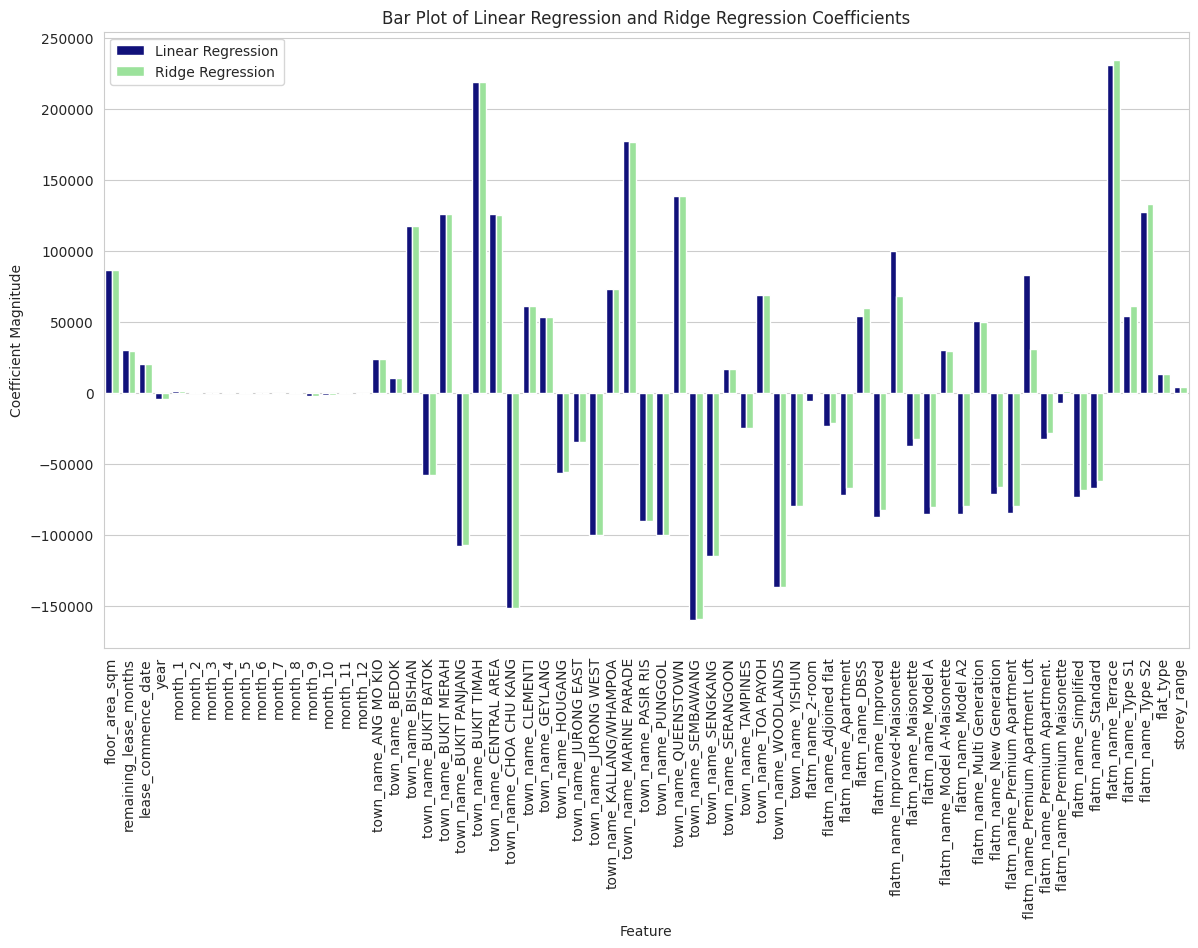

In [58]:
# Extract the coefficients of the linear regression model
lr_coefs = lr_pipeline.named_steps['regressor'].coef_

# Extract the coefficients of the ridge regression model
ridge_coefs = ridge_pipeline.named_steps['regressor'].coef_

# Assuming feature_names contains the names of the features after preprocessing
feature_names = (
    numerical_features +
    list(ridge_pipeline.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot'].get_feature_names_out(nominal_features)) +
    ordinal_features +
    passthrough_features
)

# Create a DataFrame for plotting
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Linear Regression': lr_coefs,
    'Ridge Regression': ridge_coefs
})

# Melt the DataFrame to long format for seaborn
coef_df = coef_df.melt(id_vars='Feature', var_name='Model', value_name='Coefficient')

# Plotting the coefficients with seaborn
plt.figure(figsize=(14, 8))
sns.barplot(data=coef_df, x='Feature', y='Coefficient', hue='Model', palette=['darkblue', 'lightgreen'])

plt.xlabel('Feature')
plt.ylabel('Coefficient Magnitude')
plt.title('Bar Plot of Linear Regression and Ridge Regression Coefficients')
plt.xticks(rotation=90)
plt.grid(True, axis='y')
plt.legend(loc='upper left')
plt.show()

In [59]:
from sklearn.linear_model import Lasso

# Fit Lasso Regression with default alpha
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=1))
])
lasso_pipeline.fit(X_train, y_train)

# Predict on the validation set with Lasso Regression
y_val_pred_lasso = lasso_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Lasso Regression
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

# Display the metrics for Lasso Regression
print("Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")
print(f"Lasso Validation R²: {val_r2_lasso}")

/home/vivian/miniconda3/envs/hdbenv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.149e+13, tolerance: 1.457e+11
  model = cd_fast.sparse_enet_coordinate_descent(


Lasso Regression Metrics:
Lasso Validation MAE: 42376.35265988858
Lasso Validation MSE: 3028079185.1785846
Lasso Validation RMSE: 55027.98547265368
Lasso Validation R²: 0.8584623149787531


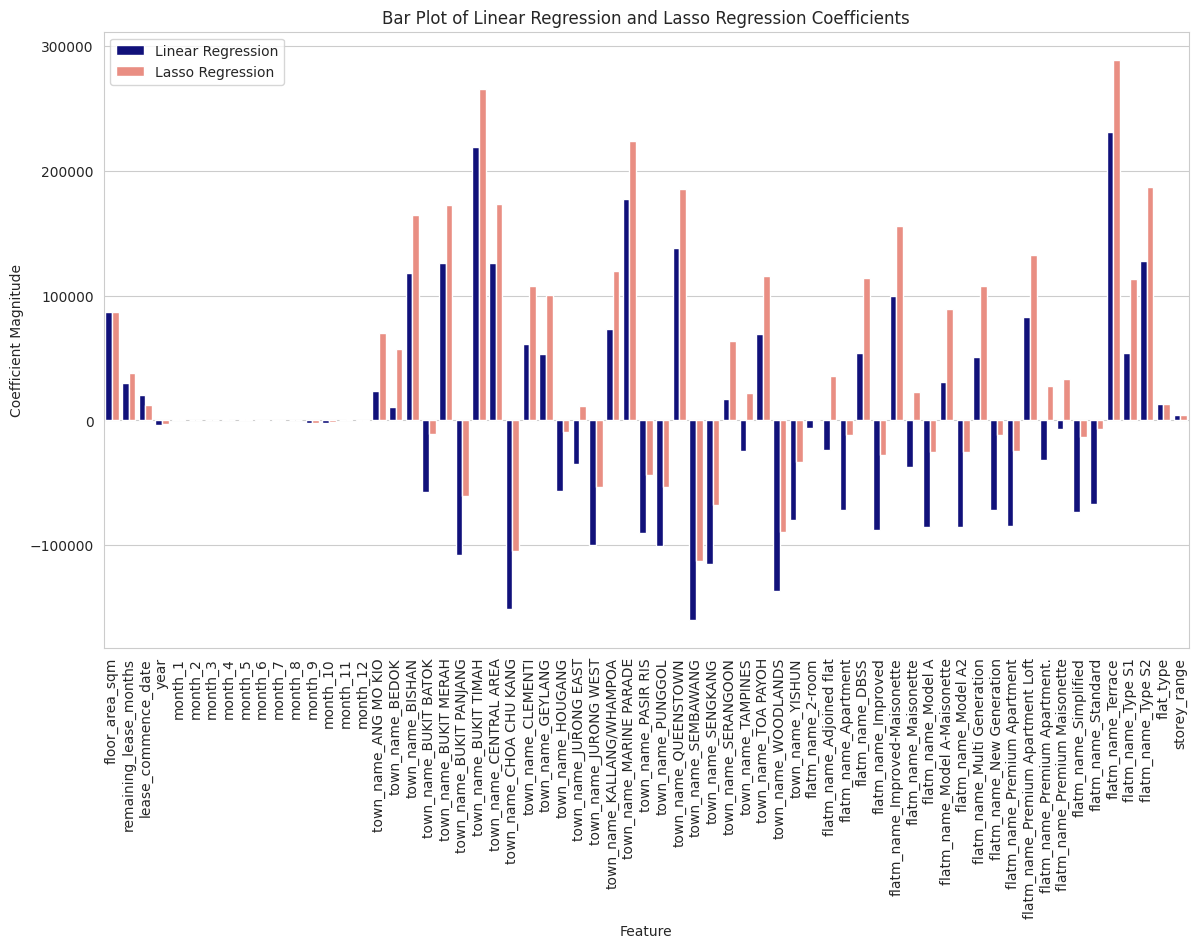

In [60]:
# Extract the coefficients of the linear and lasso regression models
lr_coefs = lr_pipeline.named_steps['regressor'].coef_
lasso_coefs = lasso_pipeline.named_steps['regressor'].coef_

# Extract feature names after preprocessing
feature_names = (
    numerical_features +
    list(preprocessor.transformers_[1][1].named_steps['onehot'].get_feature_names_out(nominal_features)) +
    ordinal_features +
    passthrough_features
)

# Create a DataFrame for plotting
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Linear Regression': lr_coefs,
    'Lasso Regression': lasso_coefs
})

# Melt the DataFrame to long format for seaborn
coef_df = coef_df.melt(id_vars='Feature', var_name='Model', value_name='Coefficient')

# Plotting the coefficients with seaborn
plt.figure(figsize=(14, 8))
sns.barplot(data=coef_df, x='Feature', y='Coefficient', hue='Model', palette=['darkblue', 'salmon'])

plt.xlabel('Feature')
plt.ylabel('Coefficient Magnitude')
plt.title('Bar Plot of Linear Regression and Lasso Regression Coefficients')
plt.xticks(rotation=90)
plt.grid(True, axis='y')
plt.legend(loc='upper left')
plt.show()

In [61]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'regressor__alpha': [0.1, 1, 10, 100, 1000],
    'regressor__fit_intercept': [True, False]
}

# Create the pipeline with a ridge regression model
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

# Create the pipeline with a lasso regression model
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso())
])

# Perform grid search with cross-validation for Ridge regression
ridge_grid_search = GridSearchCV(ridge_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
ridge_grid_search.fit(X_train, y_train)

# Perform grid search with cross-validation for Lasso regression
lasso_grid_search = GridSearchCV(lasso_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
lasso_grid_search.fit(X_train, y_train)

/home/vivian/miniconda3/envs/hdbenv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.821e+13, tolerance: 1.156e+12
  model = cd_fast.sparse_enet_coordinate_descent(
/home/vivian/miniconda3/envs/hdbenv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.834e+13, tolerance: 1.158e+12
  model = cd_fast.sparse_enet_coordinate_descent(
/home/vivian/miniconda3/envs/hdbenv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the 

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...r', Lasso())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__alpha': [0.1, 1, ...], 'regressor__fit_intercept': [True, False]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is

In [62]:
# Print the best parameters found by grid search for Ridge regression
print("Best Ridge parameters:", ridge_grid_search.best_params_)

# Print the best parameters found by grid search for Lasso regression
print("Best Lasso parameters:", lasso_grid_search.best_params_)

Best Ridge parameters: {'regressor__alpha': 0.1, 'regressor__fit_intercept': True}
Best Lasso parameters: {'regressor__alpha': 0.1, 'regressor__fit_intercept': True}


In [63]:
# Evaluate the best Ridge model on the validation set
best_ridge_model = ridge_grid_search.best_estimator_
y_val_pred_ridge = best_ridge_model.predict(X_val)

# Calculate regression metrics for validation set for Ridge
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

print("Best Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")

# Evaluate the best Lasso model on the validation set
best_lasso_model = lasso_grid_search.best_estimator_
y_val_pred_lasso = best_lasso_model.predict(X_val)

# Calculate regression metrics for validation set for Lasso
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

print("Best Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")  
print(f"Lasso Validation R²: {val_r2_lasso}")

Best Ridge Regression Metrics:
Ridge Validation MAE: 42374.2704763273
Ridge Validation MSE: 3027104696.5573497
Ridge Validation RMSE: 55019.13027808918
Ridge Validation R²: 0.8585078642709263
Best Lasso Regression Metrics:
Lasso Validation MAE: 42377.24717131365
Lasso Validation MSE: 3028324908.9033427
Lasso Validation RMSE: 55030.218143337785
Lasso Validation R²: 0.8584508294247005


In [64]:
from sklearn.model_selection import RandomizedSearchCV

# Define the parameter distributions for hyperparameter tuning
param_grid = {
    'regressor__alpha': [0.1, 1, 10, 100, 1000],
    'regressor__fit_intercept': [True, False]
}

# Create the pipeline with a ridge regression model
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

# Create the pipeline with a lasso regression model
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso())
])

# Perform randomized search with cross-validation for Ridge regression
ridge_random_search = RandomizedSearchCV(ridge_pipeline, param_distributions=param_grid, n_iter=10, cv=5, scoring='r2', random_state=42, n_jobs=-1)
ridge_random_search.fit(X_train, y_train)

# Perform randomized search with cross-validation for Lasso regression
lasso_random_search = RandomizedSearchCV(lasso_pipeline, param_distributions=param_grid, n_iter=10, cv=5, scoring='r2', random_state=42, n_jobs=-1)
lasso_random_search.fit(X_train, y_train)

/home/vivian/miniconda3/envs/hdbenv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.834e+13, tolerance: 1.158e+12
  model = cd_fast.sparse_enet_coordinate_descent(
/home/vivian/miniconda3/envs/hdbenv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.821e+13, tolerance: 1.156e+12
  model = cd_fast.sparse_enet_coordinate_descent(
/home/vivian/miniconda3/envs/hdbenv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:675: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the 

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...r', Lasso())])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__alpha': [0.1, 1, ...], 'regressor__fit_intercept': [True, False]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None ch

In [65]:
# Print the best parameters found by random search for Ridge regression
print("Best Ridge parameters:", ridge_random_search.best_params_)

# Print the best parameters found by random search for Lasso regression
print("Best Lasso parameters:", lasso_random_search.best_params_)

Best Ridge parameters: {'regressor__fit_intercept': True, 'regressor__alpha': 0.1}
Best Lasso parameters: {'regressor__fit_intercept': True, 'regressor__alpha': 0.1}


In [66]:
# Best model from Ridge regression (Grid Search)
best_ridge_model = ridge_grid_search.best_estimator_

# Predict on the test set with Ridge Regression
y_test_pred_ridge = best_ridge_model.predict(X_test)

# Calculate regression metrics for the test set for Ridge
test_mae_ridge = mean_absolute_error(y_test, y_test_pred_ridge)
test_mse_ridge = mean_squared_error(y_test, y_test_pred_ridge)
test_rmse_ridge = root_mean_squared_error(y_test, y_test_pred_ridge)
test_r2_ridge = r2_score(y_test, y_test_pred_ridge)

print("Best Ridge Regression Model, Final Test Metrics:")
print(f"Final Test MAE: {test_mae_ridge}")
print(f"Final Test MSE: {test_mse_ridge}")
print(f"Final Test RMSE: {test_rmse_ridge}")
print(f"Final Test R²: {test_r2_ridge}")

Best Ridge Regression Model, Final Test Metrics:
Final Test MAE: 41272.20422404603
Final Test MSE: 2896739634.154748
Final Test RMSE: 53821.36782129146
Final Test R²: 0.8656355212504876
